# Fase 6: Interpretabilidad con SHAP
**Tesis:** Modelo Predictivo de Resultados — Premier League 2017–2025  
**Objetivo:** Explicar las predicciones del mejor modelo (Gradient Boosting) con **SHAP values**, a nivel global y a nivel de partido individual. Esto cubre el objetivo específico 5 y la limitación/trabajo futuro del documento.  
**Input:** `Dataset/model_dataset_selected.csv`  
**Output:** `Imagenes/shap/*.png`, `resultados/shap_importancia_global.csv`, `resultados/shap_partidos_ejemplo.csv`

## ¿Qué es SHAP?
Asigna a cada feature una contribución (en log-odds) a cada predicción: valor positivo = empuja hacia "gana el local", negativo = hacia "no gana". La suma de contribuciones más el valor base reproduce la predicción del modelo. Se usa `TreeExplainer`, exacto para modelos de árboles.

In [1]:
import sys, os, warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, shap
from sklearn.ensemble import GradientBoostingClassifier
sys.path.insert(0,'.')
from utils.split_utils import expanding_window_split
os.makedirs('Imagenes/shap',exist_ok=True)
TARGET='target_home_win'
df=pd.read_csv('Dataset/model_dataset_selected.csv')
folds=expanding_window_split(df,min_train_seasons=1)
X=df.drop(columns=[TARGET,'season']); y=df[TARGET]
gb=lambda: GradientBoostingClassifier(n_estimators=400,learning_rate=0.05,max_depth=4,subsample=0.8,random_state=42)
print(X.shape, 'shap', shap.__version__)

(2973, 28) shap 0.52.0


## 1. SHAP global en cada fold (modelo entrenado solo con el pasado)
Para cada fold se entrena con el train y se calculan los SHAP sobre la temporada de test; luego se promedia |SHAP| entre folds para ver qué tan estable es la importancia.

In [2]:
imp, sv_all, X_all, last = {}, [], [], None
for i,(tr,te,trs,tes) in enumerate(folds,1):
    m=gb().fit(X.iloc[tr],y.iloc[tr])
    sv=shap.TreeExplainer(m).shap_values(X.iloc[te])
    imp[f'fold{i}']=np.abs(sv).mean(0)
    sv_all.append(sv); X_all.append(X.iloc[te])
    last=(m,te,tes,sv)
imp=pd.DataFrame(imp,index=X.columns)
imp['media']=imp.mean(1); imp['std']=imp.drop(columns='media').std(1)
imp=imp.sort_values('media',ascending=False)
imp[['media','std']].to_csv('resultados/shap_importancia_global.csv')
print(imp[['media','std']].round(4))

                             media     std
odds_home_prob              0.6564  0.1439
away_roll_corners           0.2074  0.1238
home_roll_shots             0.1858  0.1362
home_season_gd              0.1714  0.0612
away_roll_shots             0.1676  0.1127
away_season_goals_against   0.1642  0.1120
home_ground_advantage       0.1635  0.1025
market_uncertainty          0.1537  0.0660
home_roll_corners           0.1392  0.0856
home_roll_home_points       0.1387  0.0735
market_form_diff            0.1373  0.0498
home_season_goals_against   0.1293  0.0410
diff_avg_on_off             0.1174  0.0920
diff_team_discipline_per90  0.1027  0.0662
diff_team_int_per90         0.1020  0.0568
home_roll_goals_conceded    0.1005  0.0556
away_roll_goals_conceded    0.0922  0.0328
streak_clash                0.0886  0.0452
diff_player_quality         0.0884  0.0433
home_roll_away_points       0.0864  0.0627
h2h_home_goals_avg          0.0766  0.0368
diff_squad_age              0.0757  0.0369
diff_gk_cs_

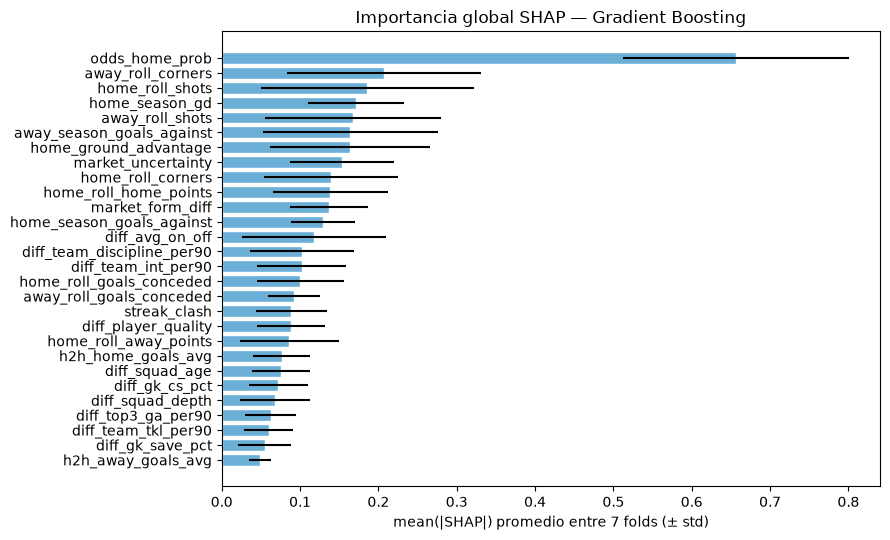

In [3]:
fig,ax=plt.subplots(figsize=(9,5.5))
s=imp.sort_values('media')
ax.barh(s.index,s['media'],xerr=s['std'],color='#6baed6',edgecolor='white')
ax.set_xlabel('mean(|SHAP|) promedio entre 7 folds (± std)'); ax.set_title('Importancia global SHAP — Gradient Boosting')
plt.tight_layout(); plt.savefig('Imagenes/shap/importancia_global.png',dpi=150,bbox_inches='tight'); plt.show()

## 2. Beeswarm (todas las temporadas de test agregadas)
Cada punto es un partido; el color indica el valor de la feature (rojo = alto) y la posición horizontal su efecto sobre la predicción.

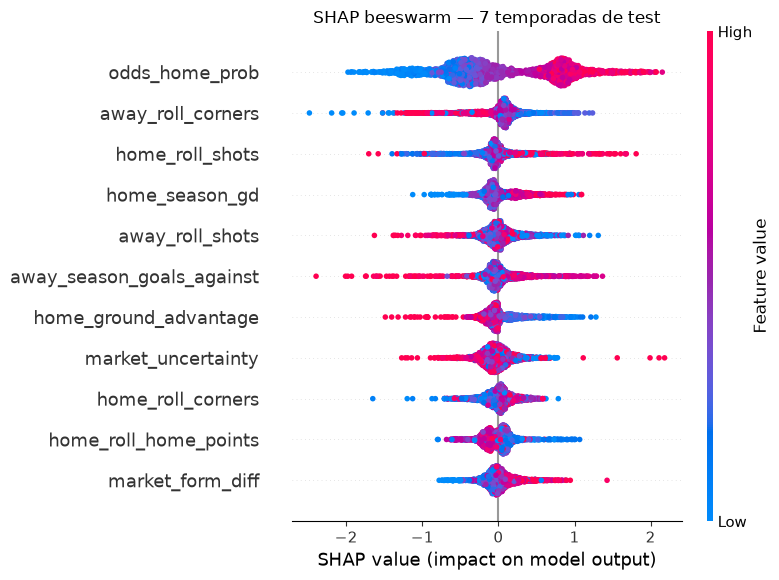

In [4]:
SV=np.vstack(sv_all); XA=pd.concat(X_all)
plt.figure(); shap.summary_plot(SV,XA,show=False,max_display=11)
plt.title('SHAP beeswarm — 7 temporadas de test'); plt.tight_layout()
plt.savefig('Imagenes/shap/beeswarm.png',dpi=150,bbox_inches='tight'); plt.show()

## 3. Dependencia de las dos features principales

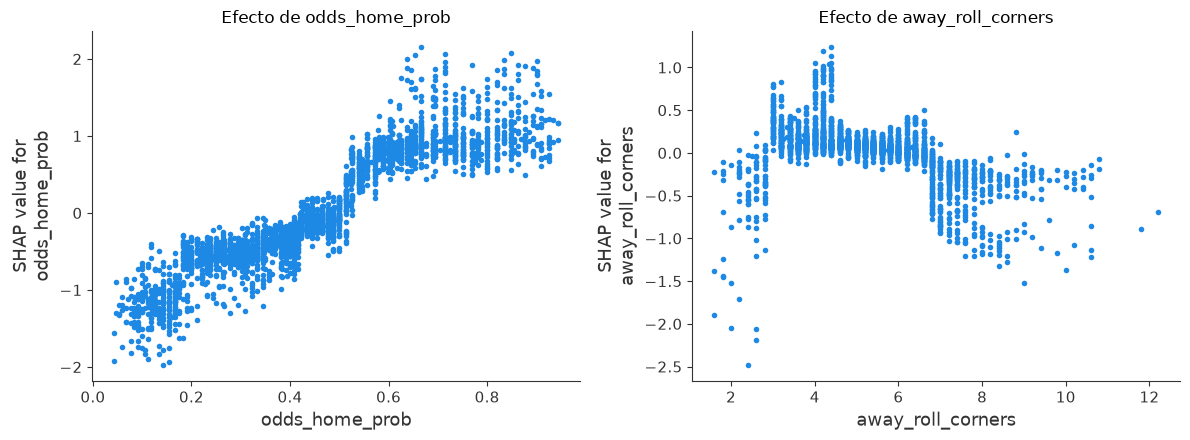

In [5]:
top=list(imp.index[:2])
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for ax,f in zip(axes,top):
    shap.dependence_plot(f,SV,XA,ax=ax,show=False,interaction_index=None)
    ax.set_title(f'Efecto de {f}')
plt.tight_layout(); plt.savefig('Imagenes/shap/dependencia_top2.png',dpi=150,bbox_inches='tight'); plt.show()

## 4. Explicación de partidos individuales (temporada 2024-25)
Un acierto con alta confianza, un error con alta confianza y un caso dudoso, para mostrar cómo decide el modelo partido a partido.

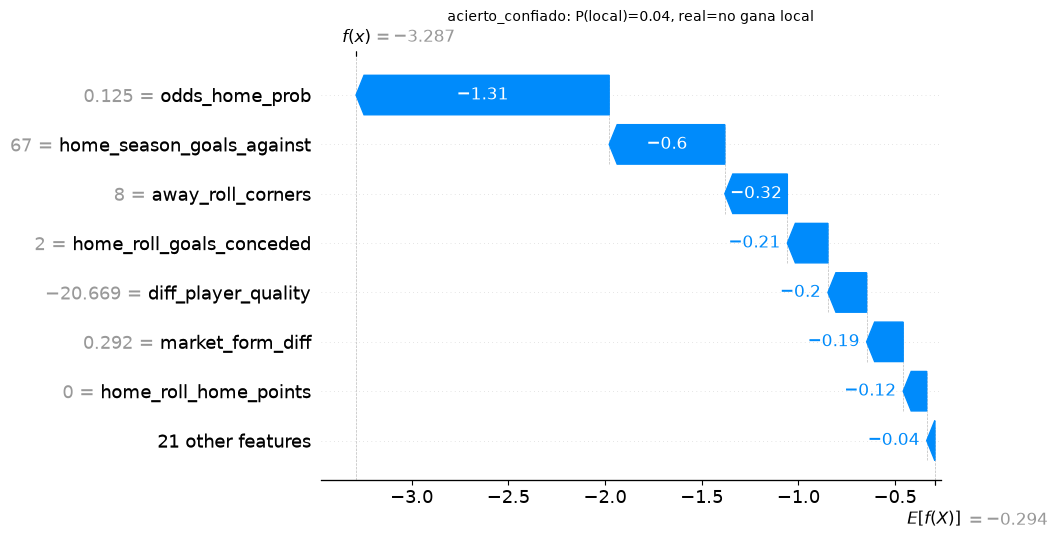

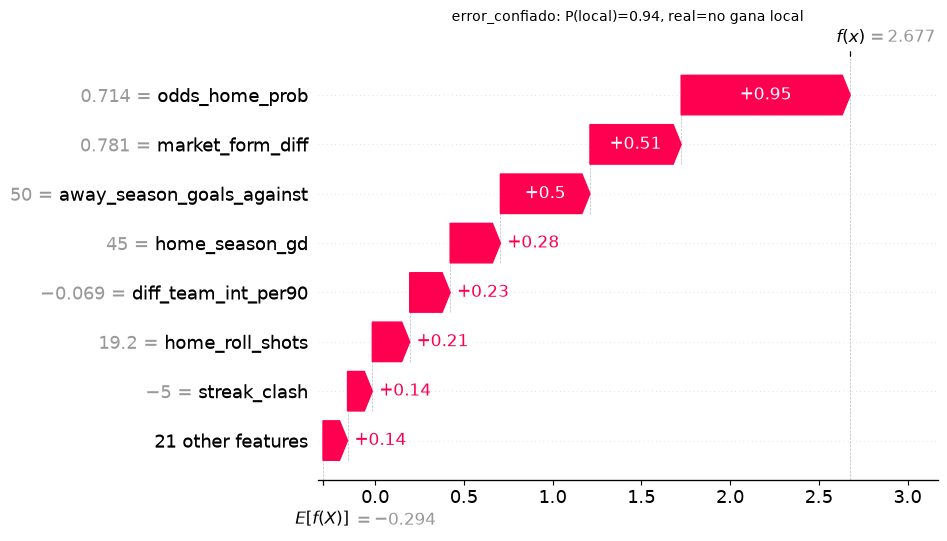

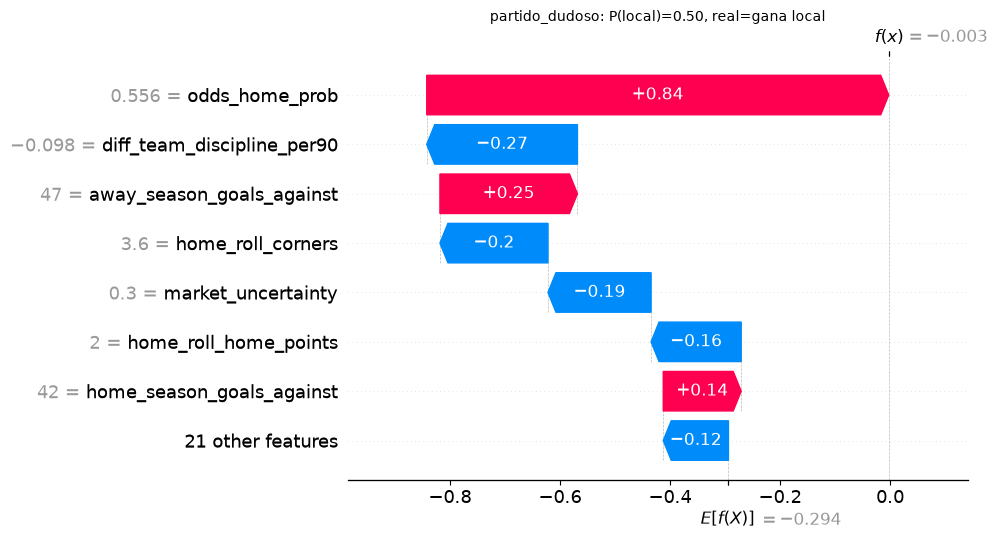

In [6]:
m,te,tes,sv=last
Xt=X.iloc[te]; yt=y.iloc[te].values
p=m.predict_proba(Xt)[:,1]; pred=(p>=.5).astype(int); ok=pred==yt
base=float(np.ravel(shap.TreeExplainer(m).expected_value)[0])
idx={'acierto_confiado':np.where(ok)[0][np.argmax(np.abs(p-.5)[ok])],
     'error_confiado':np.where(~ok)[0][np.argmax(np.abs(p-.5)[~ok])],
     'partido_dudoso':np.argmin(np.abs(p-.5))}
rows=[]
for k,j in idx.items():
    e=shap.Explanation(sv[j],base_values=base,data=Xt.iloc[j].values,feature_names=list(X.columns))
    plt.figure(); shap.plots.waterfall(e,show=False,max_display=8)
    plt.title(f'{k}: P(local)={p[j]:.2f}, real={"gana local" if yt[j] else "no gana local"}',fontsize=10)
    plt.savefig(f'Imagenes/shap/waterfall_{k}.png',dpi=150,bbox_inches='tight'); plt.show()
    rows.append({'caso':k,'fila':int(Xt.index[j]),'prob_local':round(p[j],3),'real':int(yt[j]),
                 **{f'shap_{c}':round(v,3) for c,v in zip(X.columns,sv[j])}})
pd.DataFrame(rows).to_csv('resultados/shap_partidos_ejemplo.csv',index=False)

## 5. Conclusiones
Revisar `resultados/shap_importancia_global.csv`: compara el ranking SHAP con la importancia Gini y la de permutación de `06_features_negativos.ipynb`.